## 08 Repeated Route Choice Tradeoffs (Flag 8)

### Dataset Overview
Twenty-four repeated-trip summaries and point-level traces expose route frequency, travel-time variability, a midway route switch, and speed–distance trade-offs.

The notebook exposes a primary table and a supporting table (`08_repeated_route_choice_tradeoffs_points.csv`).

Goal: Analyze how the traveler selects routes across repeated trips and identify the trade-offs that appear to shape their route choices.

Role: Repeated-trip mobility analyst


Category: Route Choice and Movement Behavior

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "08_repeated_route_choice_tradeoffs.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "08_repeated_route_choice_tradeoffs_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: Which route is selected most often across similar trips, and how does its travel-time variability compare with the alternatives?

#### Analysis action

Compare route counts and complete travel-time distributions rather than only their means.

              count       mean       std
route_choice                            
A                13  31.638462  0.619864
B                 6  33.550000  7.149196
C                 4  34.925000  6.702922


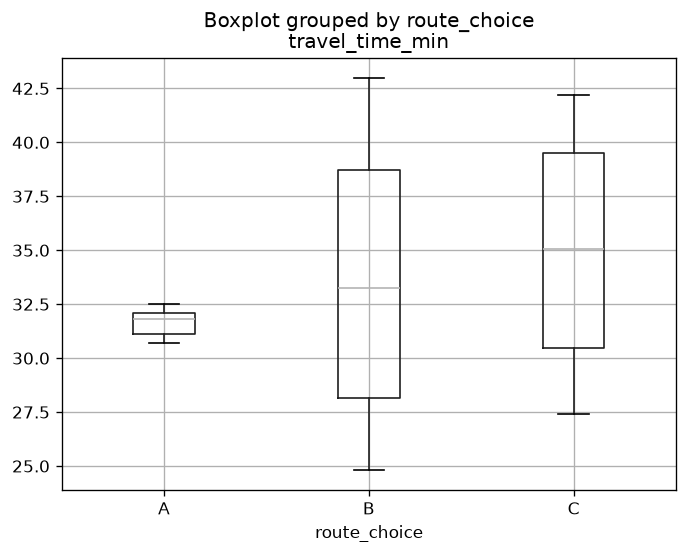

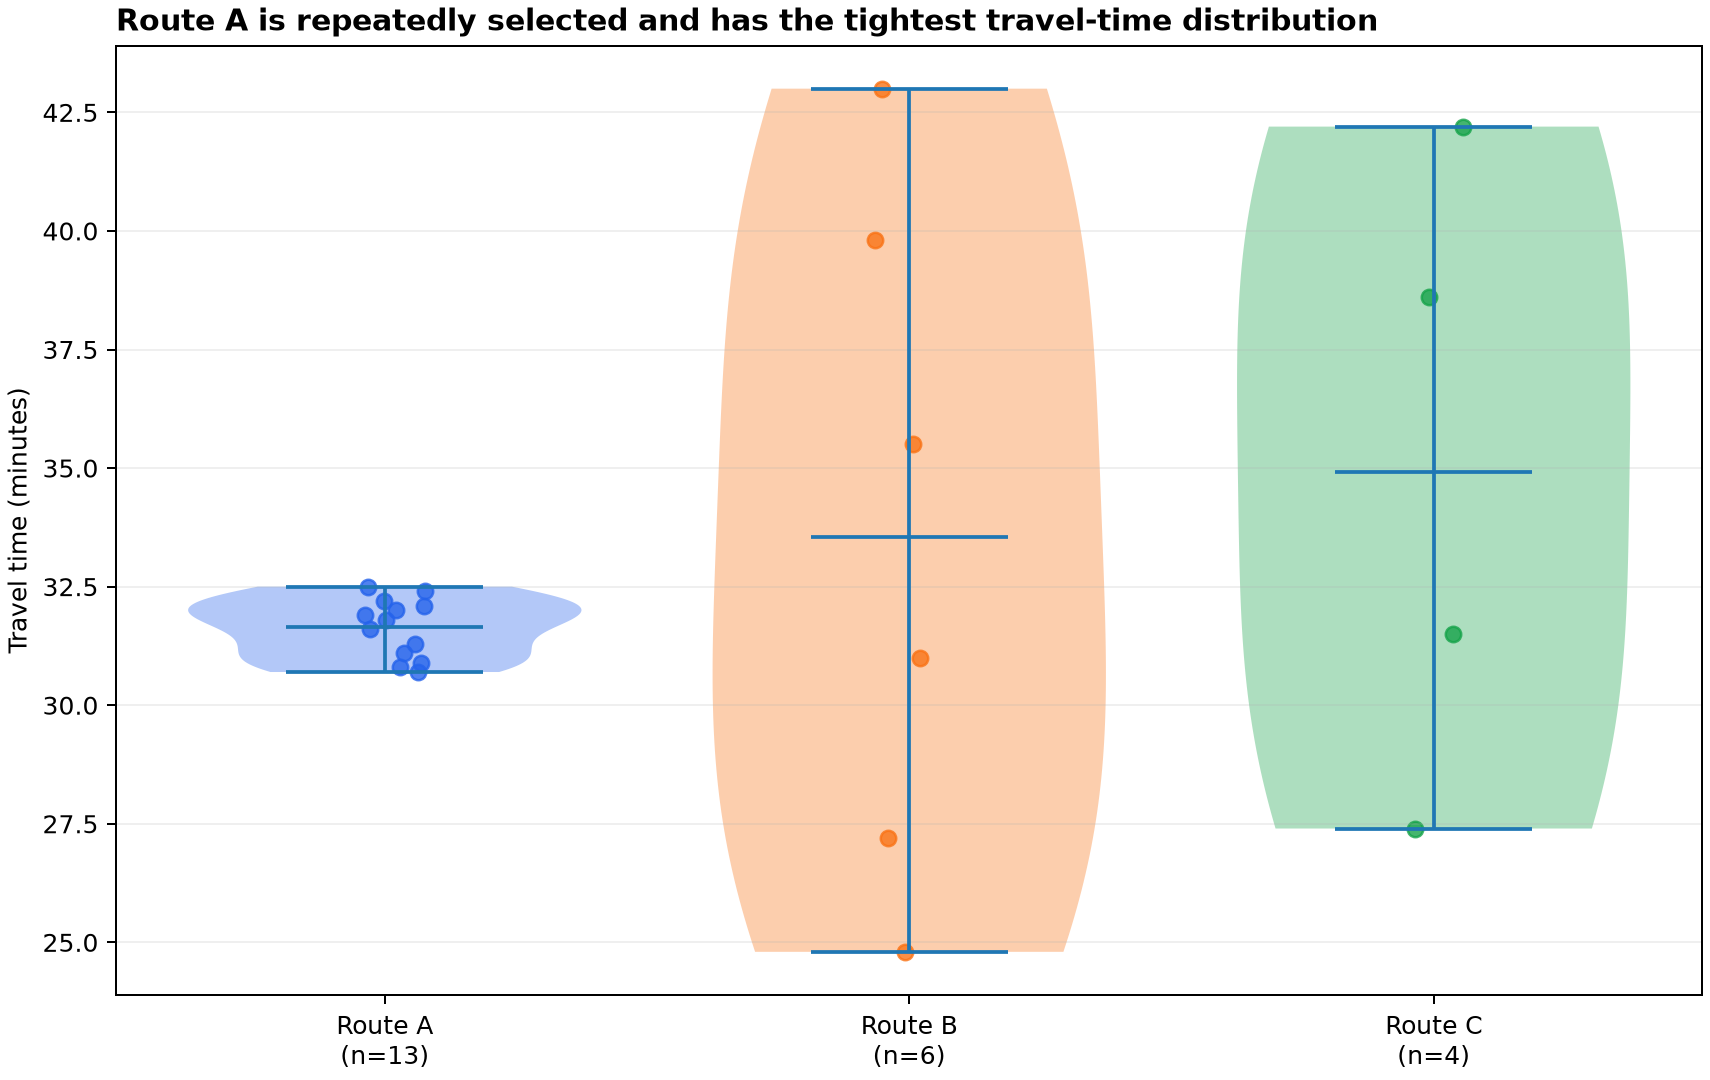

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
d=df[df.route_choice.isin(['A','B','C'])]; print(d.groupby('route_choice').travel_time_min.agg(['count','mean','std'])); d.boxplot(column='travel_time_min',by='route_choice'); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/route_choice_time_distribution.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "route_time_distribution",
  "insight_type": "group_comparison",
  "insight": "Although Route A is not always the fastest option, the traveler repeatedly chooses it across similar trips, and its travel time varies substantially less than the alternatives.",
  "insight_value": {
    "route_a_count": 13,
    "route_a_time_std_min": 0.6,
    "alternative_time_std_min": {
      "B": 6.53,
      "C": 5.8
    }
  },
  "plot": {
    "plot_type": "route_time_distribution",
    "title": "Route Choice and Travel-Time Variability",
    "file": "visualizations/route_choice_time_distribution.png",
    "description": "Violin and point distributions compare selection frequency and travel-time variability."
  },
  "question": "Which route is selected most often across similar trips, and how does its travel-time variability compare with the alternatives?",
  "actionable_insight": "Compare route counts and complete travel-time distributions rather than only their means.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd=df[df.route_choice.isin(['A','B','C'])]; print(d.groupby('route_choice').travel_time_min.agg(['count','mean','std'])); d.boxplot(column='travel_time_min',by='route_choice'); plt.show()",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_id",
    "trajectory_timestamp"
  ]
}

### **Question 2**: Does any trip depart from the habitual corridor midway and reconnect near the destination?

#### Analysis action

Compare the highlighted point sequence with repeated Route A traces.

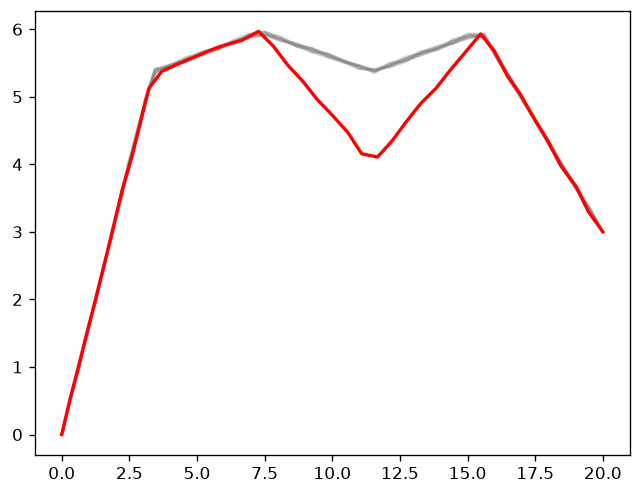

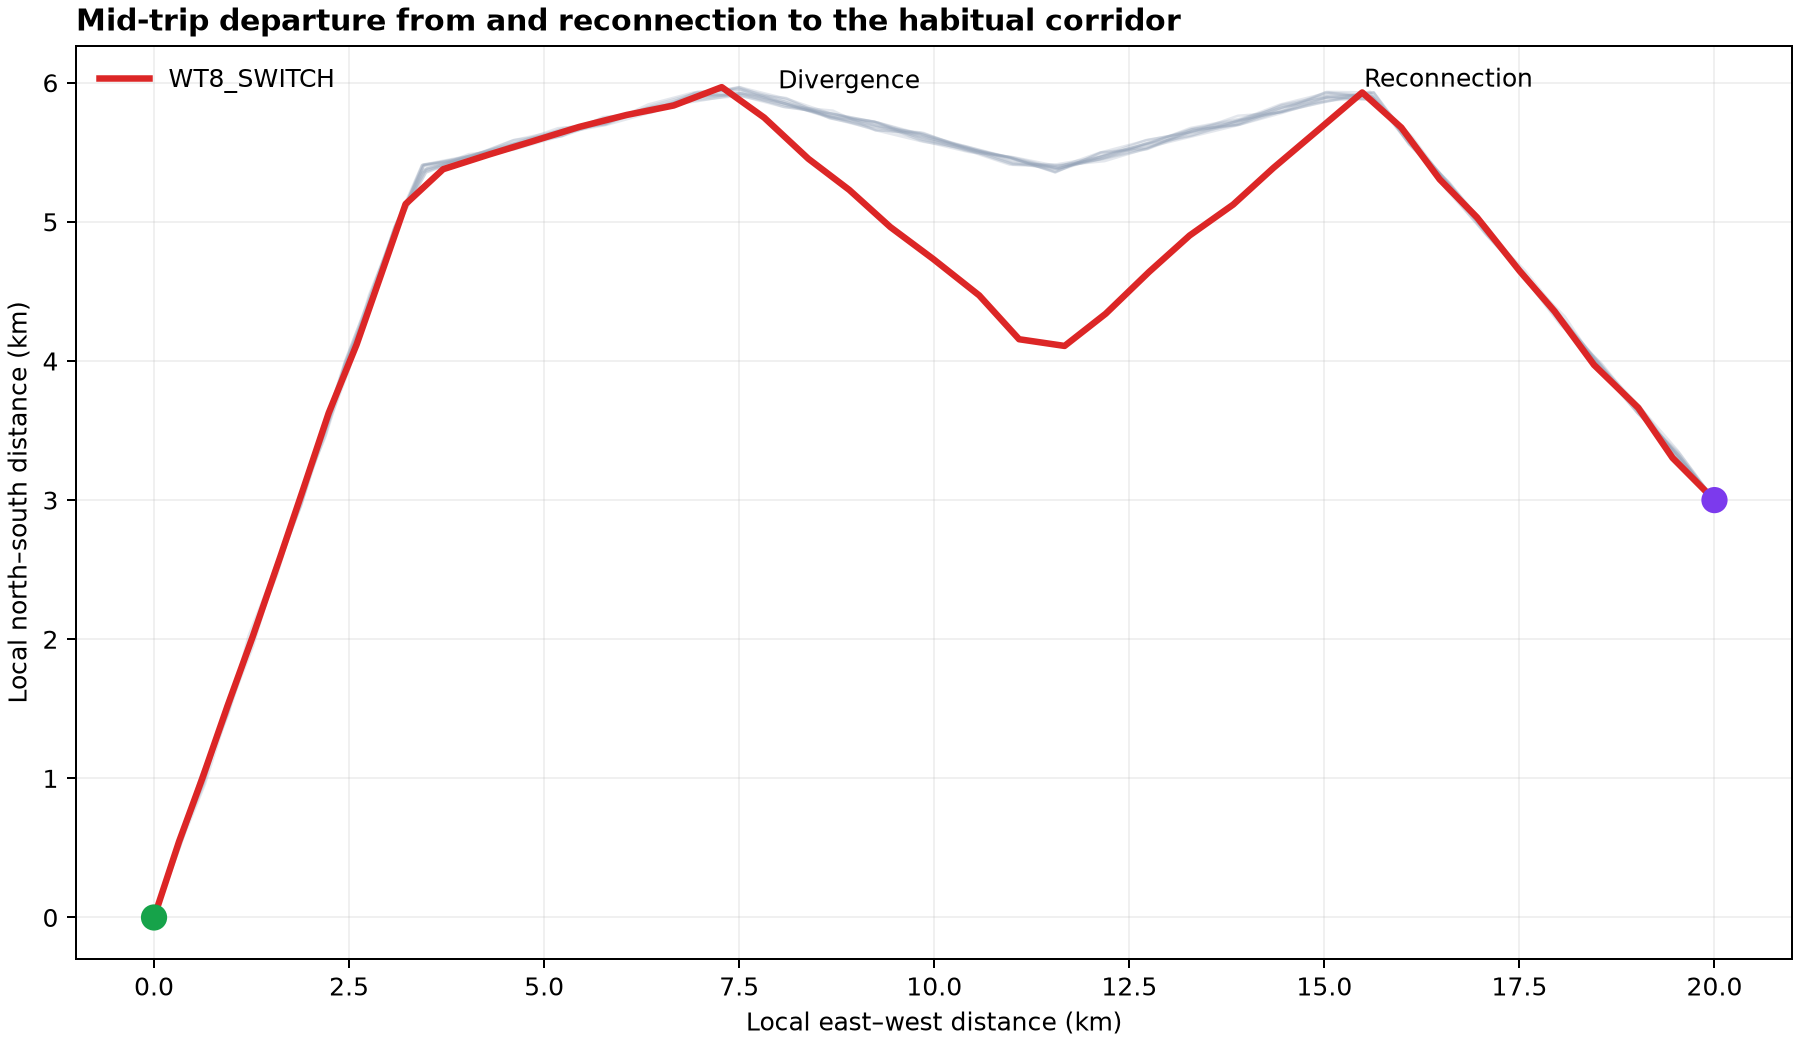

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
t=user_df.copy(); normal=t[t.route_choice.eq('A')]; switch=t[t.trajectory_id.eq('WT8_SWITCH')];
for _,g in normal.groupby('trajectory_id'): plt.plot(g.x_km,g.y_km,color='gray',alpha=.2)
plt.plot(switch.x_km,switch.y_km,color='red',linewidth=2); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/midway_switch_reconnection.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "route_switch_map",
  "insight_type": "temporal_dynamics",
  "insight": "Most trips follow the same familiar corridor, but this journey switches to a different route midway and reconnects with the habitual route near the destination.",
  "insight_value": {
    "trajectory_id": "WT8_SWITCH",
    "divergence_progress": 0.4,
    "reconnection_progress": 0.8
  },
  "plot": {
    "plot_type": "route_switch_map",
    "title": "Midway Route Switch",
    "file": "visualizations/midway_switch_reconnection.png",
    "description": "Repeated Route A traces provide the habitual corridor; the highlighted trip diverges and reconnects."
  },
  "question": "Does any trip depart from the habitual corridor midway and reconnect near the destination?",
  "actionable_insight": "Compare the highlighted point sequence with repeated Route A traces.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nt=user_df.copy(); normal=t[t.route_choice.eq('A')]; switch=t[t.trajectory_id.eq('WT8_SWITCH')];\nfor _,g in normal.groupby('trajectory_id'): plt.plot(g.x_km,g.y_km,color='gray',alpha=.2)\nplt.plot(switch.x_km,switch.y_km,color='red',linewidth=2); plt.show()",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_id"
  ]
}

### **Question 3**: How can the selected route achieve travel time comparable to the shorter alternative despite covering more distance?

#### Analysis action

Compare speed level and variability throughout the trip together with total distance and time.

   trajectory_id  distance_km  travel_time_min  mean_speed_kmh  speed_std_kmh
0         WT8_01    23.977078             31.1       46.258028       0.794847
15        WT8_16    20.270606             31.0       39.233431       3.059664


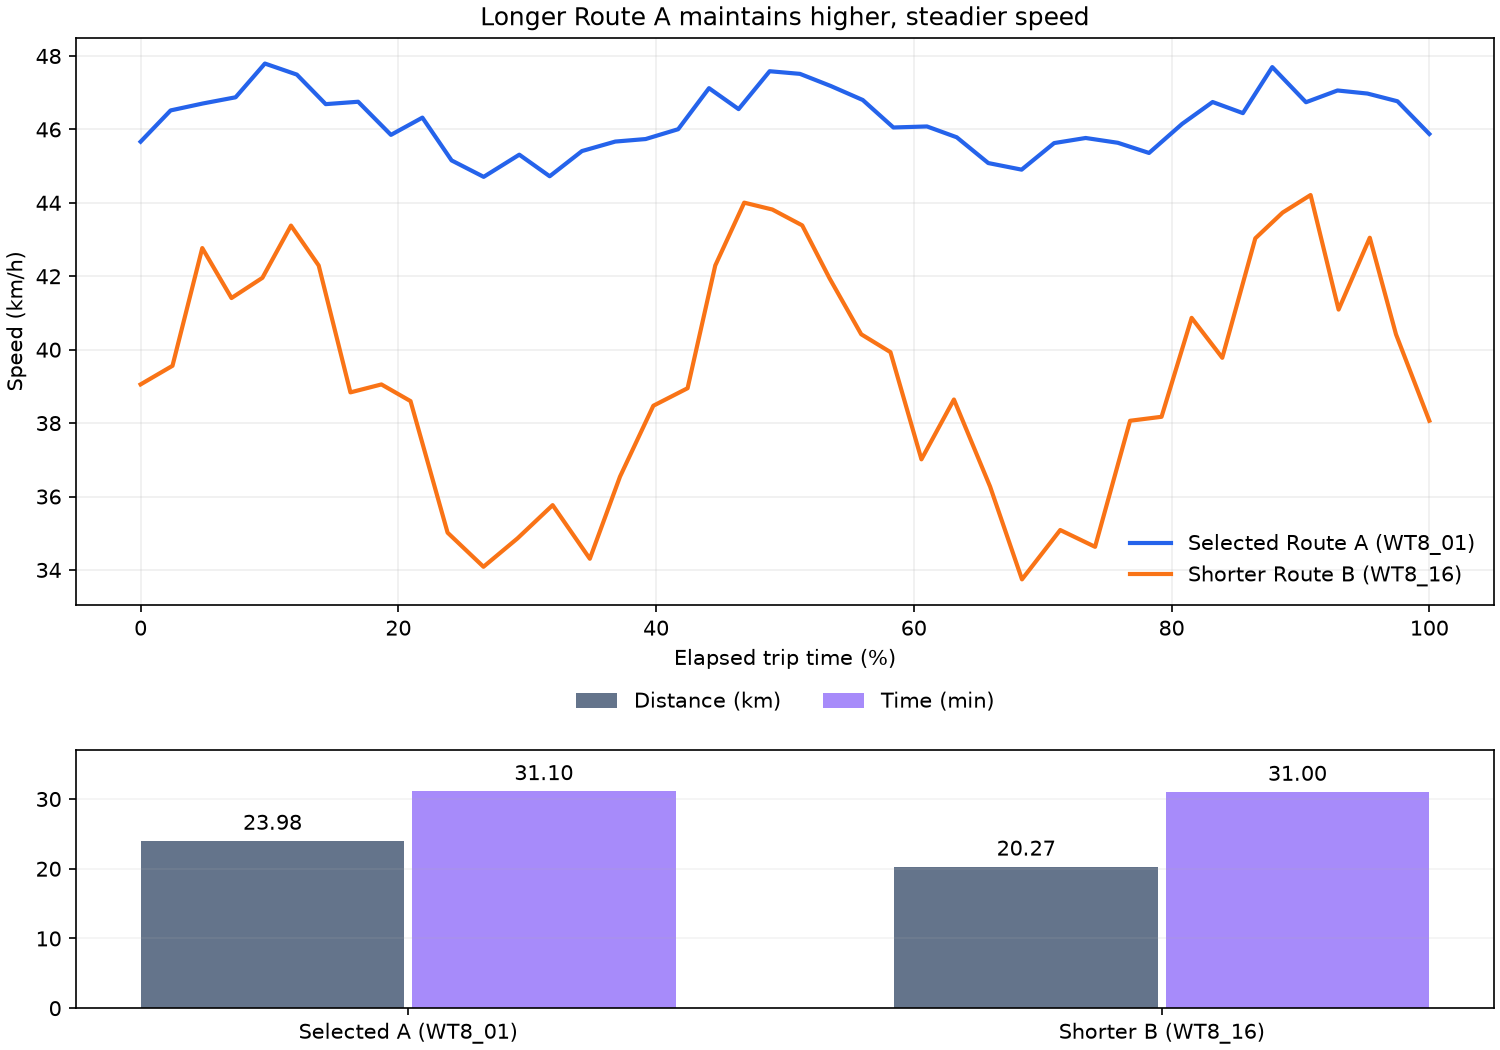

In [3]:
# Retain the original analysis; its speed plot is already included in the combined figure.
from unittest.mock import patch as _patch_plot_display
import matplotlib.pyplot as plt
with plt.ioff(), _patch_plot_display('matplotlib.pyplot.show', side_effect=lambda: plt.close(plt.gcf())):
    import pandas as pd
    import matplotlib.pyplot as plt
    d=df[df.trajectory_id.isin(['WT8_01','WT8_16'])]; print(d[['trajectory_id','distance_km','travel_time_min','mean_speed_kmh','speed_std_kmh']]); t=user_df[user_df.trajectory_id.isin(d.trajectory_id)];
    for tid,g in t.groupby('trajectory_id'): plt.plot(g.elapsed_fraction,g.speed_kmh,label=tid)
    plt.legend(); plt.show()
# Display one combined figure containing the speed profile and trip totals.
from IPython.display import Image, display
display(Image(filename='visualizations/longer_route_speed_tradeoff.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "speed_distance_tradeoff",
  "insight_type": "factor_relationship",
  "insight": "The selected route is longer than the shorter alternative, but it maintains higher and more stable speeds for most of the trip, resulting in a comparable overall travel time.",
  "insight_value": {
    "selected_route": {
      "id": "WT8_01",
      "distance_km": 24.0,
      "time_min": 31.1
    },
    "shorter_route": {
      "id": "WT8_16",
      "distance_km": 20.0,
      "time_min": 31.0
    }
  },
  "plot": {
    "plot_type": "speed_distance_tradeoff",
    "title": "Distance, Speed Stability, and Travel Time",
    "file": "visualizations/longer_route_speed_tradeoff.png",
    "description": "Speed profiles and trip totals compare the selected longer route with the shorter alternative."
  },
  "question": "How can the selected route achieve travel time comparable to the shorter alternative despite covering more distance?",
  "actionable_insight": "Compare speed level and variability throughout the trip together with total distance and time.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd=df[df.trajectory_id.isin(['WT8_01','WT8_16'])]; print(d[['trajectory_id','distance_km','travel_time_min','mean_speed_kmh','speed_std_kmh']]); t=user_df[user_df.trajectory_id.isin(d.trajectory_id)];\nfor tid,g in t.groupby('trajectory_id'): plt.plot(g.elapsed_fraction,g.speed_kmh,label=tid)\nplt.legend(); plt.show()",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_id",
    "trajectory_timestamp"
  ]
}

### Summary of Findings (Flag 8)

Across similar trips, Route A is the most frequent and most predictable choice even though alternatives can be faster. One trip temporarily leaves the habitual corridor, and the detailed comparison shows how a longer but faster and steadier route can match the travel time of a shorter alternative.

### Data definitions

**distance_km**: Sum of Euclidean distances between consecutive x_km/y_km points.

**elapsed_fraction**: Elapsed time / total travel time; irregular sampling. No absolute timestamps are available.

**speed_kmh**: Point speed, linearly interpolated in elapsed time between adjacent samples. Its integral on each segment equals segment distance.

**mean_speed_kmh**: Time-weighted mean speed = distance_km / (travel_time_min / 60).

**speed_std_kmh**: Population standard deviation over elapsed time, integrating the square of piecewise-linear speed. Not unweighted standard deviation of sampled points.

**travel_time_std**: GT uses population standard deviation (ddof=0); the original analysis code displays pandas sample standard deviation (ddof=1).

**insight_3_distance_precision**: Accepted insight_value distances 24.0 and 20.0 are whole-kilometre approximations; exact distances are in the CSV.

**insight_3_comparator**: WT8_16 is the representative trip on the shorter Route B alternative, not the minimum-distance trip across all records.